# EDA del corpus de tópicos y auditoría de la partición

Bloque 2 (modelado de tópicos con BERTopic). Machine Learning 2026/27, competición de Kaggle *Contradictory, My Dear Watson*.

Este notebook prepara el terreno para BERTopic. Define qué es un documento, cuántos hay, en qué idiomas están, cuánto miden, cómo están repartidas las clases y qué muletillas aparecen. También revisa la partición train/val del Bloque 1. No ajusta ningún modelo.

Datos que usa (ya están en el repositorio, generados en el Bloque 1):
- la partición train/val: `experiments/results/validation/historical_split/train.csv` y `val.csv`;
- el train oficial con premisa e hipótesis traducidas al inglés: `experiments/results/translation/corpus/train_gemma3_4b.csv`.

El modelo de embeddings se descarga de HuggingFace la primera vez que se ejecuta.

Para ejecutarlo, desde la raíz del repo y con el entorno virtual activado:

```
python -m jupyter nbconvert --to notebook --execute --inplace experiments/notebooks/topic_eda.ipynb
```

Orden: primero `topic_eda.ipynb` y después `topic_modeling.ipynb`.
Semilla: `SEED = 42` en todo. Las versiones de los paquetes se imprimen en la primera celda de código.

In [1]:
import platform, importlib.metadata as md

SEED = 42  # semilla única para todo lo aleatorio (UMAP, K-means, muestras), así los resultados se repiten


def versiones(paquetes):
    """Devuelve (paquete, versión) para dejar constancia del entorno en el que se ejecutó el notebook."""
    filas = [("python", platform.python_version())]
    for p in paquetes:
        try:
            filas.append((p, md.version(p)))
        except md.PackageNotFoundError:
            filas.append((p, "no instalado"))
    return filas

import re
from pathlib import Path
import pandas as pd
from IPython.display import display

import matplotlib as mpl
import matplotlib.pyplot as plt

# Colores fijos para que el mismo concepto tenga siempre el mismo color en todas las figuras.
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#8a5cd1", "#c23b3b"]
GRIS, GRIS_CLARO = "#8f8e88", "#d9d8d3"  # para "otros tópicos" y para los outliers
COLOR_CLASE = {"entailment": PALETA[0], "neutral": PALETA[1], "contradiction": PALETA[2]}

# Estilo sobrio: sin bordes superior/derecho y rejilla suave.
mpl.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})

pd.set_option("display.max_colwidth", 120)

for p, v in versiones(["numpy", "pandas", "matplotlib"]):
    print(f"{p:12s} {v}")

python       3.11.9
numpy        2.4.6
pandas       3.1.1
matplotlib   3.11.2


## 0. Configuración

- `TEXT_COL` es la columna de texto que usará BERTopic. Usamos el texto traducido al inglés (`premise_translated`), el mismo con el que funciona mejor el modelo con n-gramas del Bloque 1. Cambiándola a `"premise"` se repite todo con el texto original.
- Los CSV se leen con `id` como texto y `keep_default_na=False`, igual que en el Bloque 1, para que un texto como `"NA"` no se convierta en un valor vacío.

In [2]:
TEXT_COL = "premise_translated"                          # texto que verá BERTopic ("premise" = original)
OPT = {"dtype": {"id": str}, "keep_default_na": False}    # opciones de lectura comunes a todos los CSV


def raiz_repo():
    """Carpeta raíz del repositorio, para que el notebook funcione se abra desde donde se abra."""
    for carpeta in (Path.cwd(), *Path.cwd().parents):
        if (carpeta / "requirements.txt").is_file():
            return carpeta
    raise FileNotFoundError("Ejecuta el notebook dentro del repositorio.")


ROOT = raiz_repo()


def buscar(*rutas):
    """Primera ruta que exista. Los datos del Bloque 1 están en experiments/results/ (antes en artifacts/)."""
    for r in rutas:
        if (ROOT / r).exists():
            return ROOT / r
    raise FileNotFoundError(f"No se encuentra ninguna de estas rutas: {rutas}")


SPLITS = buscar("experiments/results/validation/historical_split", "artifacts/splits")
TRADUCCION = buscar("experiments/results/translation/corpus/train_gemma3_4b.csv",
                    "artifacts/translations/train_gemma3_4b.csv")
LABELS = {0: "entailment", 1: "neutral", 2: "contradiction"}

## 1. Carga y unión con la partición del Bloque 1

`train_gemma3_4b.csv` contiene las 12.120 filas del `train.csv` oficial con dos columnas más, `premise_translated` e `hypothesis_translated`. Las filas en inglés se copian tal cual. Cada fila se une por `id` con la partición del grupo para saber si está en train o en val (columna `part`).

In [3]:
# Datos con traducción y los IDs de cada parte de la partición del Bloque 1.
df = pd.read_csv(TRADUCCION, **OPT)
split_train = pd.read_csv(SPLITS / "train.csv", **OPT)
split_val = pd.read_csv(SPLITS / "val.csv", **OPT)

# Columna "part" = train / val, unida por id (validate asegura que cada id aparece una sola vez).
parts = pd.concat([split_train[["id"]].assign(part="train"), split_val[["id"]].assign(part="val")])
df = df.merge(parts, on="id", how="left", validate="one_to_one")
assert df["part"].notna().all() and len(df) == 12120  # todas las filas tienen parte asignada

# Comprobación: el CSV traducido conserva intactas las columnas originales de la partición.
check = df.set_index("id").loc[split_train.id].reset_index()[split_train.columns]
pd.testing.assert_frame_equal(check, split_train)

df["clase"] = df["label"].map(LABELS)  # nombre legible de la clase
print(df.shape)
display(df.head(3))

(12120, 10)


,id,premise,hypothesis,lang_abv,language,label,premise_translated,hypothesis_translated,part,clase
0,5130fd2cb5,and these comments were considered in formulating the interim rules.,The rules developed in the interim were put together with these comments in mind.,en,English,0,and these comments were considered in formulating the interim rules.,The rules developed in the interim were put together with these comments in mind.,train,entailment
1,5b72532a0b,"These are issues that we wrestle with in practice groups of law firms, she said.",Practice groups are not permitted to work on these issues.,en,English,2,"These are issues that we wrestle with in practice groups of law firms, she said.",Practice groups are not permitted to work on these issues.,train,contradiction
2,3931fbe82a,Des petites choses comme celles-là font une différence énorme dans ce que j'essaye de faire.,J'essayais d'accomplir quelque chose.,fr,French,0,Small things like these make a huge difference in what I'm trying to do.,I was trying to accomplish something.,val,entailment


## 2. Filas y premisas distintas por idioma y por parte

Una premisa distinta se identifica por su texto original (`premise`). Ninguna premisa original aparece en dos idiomas, así que deduplicar por el texto original es seguro.

In [4]:
print("Filas:", len(df), "| premisas originales distintas:", df.premise.nunique(),
      "| premisas traducidas distintas:", df.premise_translated.nunique())
# Si alguna premisa tuviera más de un idioma, el máximo sería > 1.
print("Idiomas por premisa (máximo):", df.groupby("premise").lang_abv.nunique().max())

# Tabla idioma x parte con número de filas y de premisas distintas.
por_idioma = (df.groupby(["language", "part"])
                .agg(filas=("id", "size"), premisas=("premise", "nunique"))
                .unstack("part", fill_value=0))
por_idioma.columns = [f"{a}_{b}" for a, b in por_idioma.columns]
por_idioma["filas_total"] = por_idioma.filas_train + por_idioma.filas_val
por_idioma = por_idioma.sort_values("filas_total", ascending=False)
por_idioma.loc["TOTAL"] = por_idioma.sum()
display(por_idioma)

Filas: 12120 | premisas originales distintas: 8209 | premisas traducidas distintas: 8404
Idiomas por premisa (máximo): 1


,filas_train,filas_val,premisas_train,premisas_val,filas_total
language,,,,,
English,5516,1354,3047,1190,6870
Chinese,308,103,299,101,411
Arabic,322,79,303,79,401
French,331,59,314,59,390
Swahili,313,72,298,72,385
Urdu,311,70,300,70,381
Vietnamese,312,67,301,67,379
Russian,282,94,266,94,376
Hindi,288,86,269,83,374


### 2.1. Traducciones de una misma premisa

La traducción se hizo por par, así que una premisa que aparece en 2 o 3 filas puede tener traducciones ligeramente distintas. Para BERTopic se usa la primera traducción de cada premisa (en el orden del CSV). Es una regla fija que no depende de la etiqueta.

In [5]:
# Número de traducciones distintas que tiene cada premisa original.
n_trad = df.groupby("premise").premise_translated.nunique()
print("Premisas con más de una traducción distinta:", int((n_trad > 1).sum()), "de", len(n_trad))

# Un ejemplo para verlo.
ejemplo = n_trad[n_trad > 1].index[0]
display(df.loc[df.premise == ejemplo, ["lang_abv", "premise", "premise_translated"]])

Premisas con más de una traducción distinta: 198 de 8209


,lang_abv,premise,premise_translated
4366,vi,"' Ý sâu xa của tôi là để thành công hoàn toàn, một từ điển loại này cần nhiều hơn là kỹ năng sách vở của một chuyên ...","'My deep thought is to achieve complete success, a dictionary of this type needs more than just the bookish skills o..."
6329,vi,"' Ý sâu xa của tôi là để thành công hoàn toàn, một từ điển loại này cần nhiều hơn là kỹ năng sách vở của một chuyên ...","'My deep thought is to succeed completely, a dictionary of this type needs more than just the bookish skills of a sp..."


### 2.2. Premisas que no se tradujeron

Al revisar los ejemplos (sección 7) aparecen premisas "traducidas" que siguen en su idioma original. Aquí se cuentan las filas no inglesas cuya traducción es idéntica al original o está escrita sobre todo en un alfabeto no latino.

In [6]:
ne = df[df.lang_abv != "en"].copy()  # solo filas no inglesas


def frac_no_latina(s):
    """Fracción de letras del texto que no son del alfabeto latino (árabe, chino, cirílico...)."""
    letras = [c for c in s if c.isalpha()]
    return sum(ord(c) > 591 for c in letras) / max(1, len(letras))  # 591 = último carácter latino extendido


# Sin traducir = la "traducción" es igual al original, o más del 30 % de sus letras no son latinas.
ne["sin_traducir"] = ne.premise.eq(ne.premise_translated) | ne.premise_translated.map(frac_no_latina).gt(0.3)
print(f"Filas no inglesas: {len(ne)} | premisa sin traducir: {int(ne.sin_traducir.sum())} ({ne.sin_traducir.mean():.1%})")

tabla = ne.groupby("language").sin_traducir.agg(filas="size", sin_traducir="sum")
tabla["%"] = (100 * tabla.sin_traducir / tabla.filas).round(1)
display(tabla.sort_values("%", ascending=False).T)

Filas no inglesas: 5250 | premisa sin traducir: 1767 (33.7%)

language,Chinese,Hindi,Russian,Spanish,Thai,Urdu,Vietnamese,Arabic,Turkish,German,French,Swahili,Greek,Bulgarian
filas,411.0,374.0,376.0,366.0,371.0,381.0,379.0,401.0,351.0,351.0,390.0,385.0,372.0,342.0
sin_traducir,312.0,252.0,149.0,136.0,132.0,125.0,110.0,113.0,92.0,77.0,85.0,70.0,60.0,54.0
%,75.9,67.4,39.6,37.2,35.6,32.8,29.0,28.2,26.2,21.9,21.8,18.2,16.1,15.8


Alrededor de un tercio de las premisas no inglesas no se tradujo; en chino, unas tres de cada cuatro. El traductor del Bloque 1 (el módulo de traducción con Ollama) comprueba que la respuesta de Ollama tenga los IDs correctos y no esté vacía, pero no que el texto sea distinto del original. `gemma3:4b` a veces devolvía la frase sin cambiar y se aceptaba como traducción.

Para los tópicos esto significa que esas premisas llegan a BERTopic en su idioma original. El modelo de embeddings es multilingüe, así que una frase y su traducción quedan cerca y el clustering no debería separarlas por idioma, aunque c-TF-IDF sí puede mostrar alguna palabra no inglesa. En `topic_modeling.ipynb` se mide si los tópicos agrupan por idioma.

## 3. Repeticiones de premisas

Cuántas premisas aparecen 1, 2 o 3 veces (cada vez con una hipótesis distinta).

In [7]:
# value_counts() dos veces: primero cuántas veces aparece cada premisa, luego cuántas premisas hay con 1, 2, 3 apariciones.
rep = pd.DataFrame({
    "todas": df.premise.value_counts().value_counts(),
    "solo train": df[df.part == "train"].premise.value_counts().value_counts(),
    "solo val": df[df.part == "val"].premise.value_counts().value_counts(),
}).fillna(0).astype(int).sort_index()
rep.index.name = "veces que aparece"
display(rep)

filas_en_repetidas = df.premise.map(df.premise.value_counts()).gt(1).sum()
print(f"Filas cuya premisa aparece más de una vez: {filas_en_repetidas} ({filas_en_repetidas/len(df):.1%})")

,todas,solo train,solo val
veces que aparece,,,
1,5409,4975,2081
2,1689,1507,164
3,1111,569,5


Filas cuya premisa aparece más de una vez: 6711 (55.4%)


## 4. Longitud en palabras

Palabras de la premisa traducida (una vez por premisa distinta) y de la hipótesis traducida (una vez por fila).

,count,mean,std,min,25%,50%,75%,max
premisa (distinta),8209.0,18.0,11.6,1.0,10.0,16.0,24.0,196.0
hipótesis (fila),12120.0,9.9,4.6,1.0,7.0,9.0,12.0,46.0


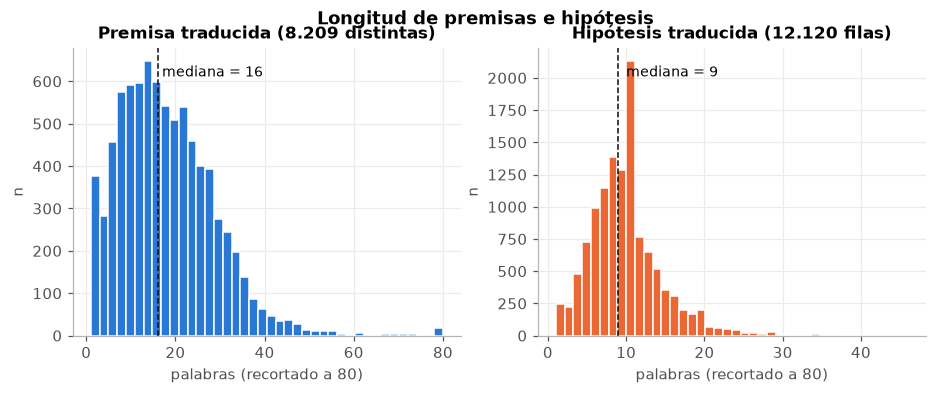

In [8]:
prem_unicas = df.drop_duplicates("premise")                    # una fila por premisa
len_p = prem_unicas[TEXT_COL].str.split().str.len()            # palabras separadas por espacios
len_h = df["hypothesis_translated"].str.split().str.len()
display(pd.DataFrame({"premisa (distinta)": len_p.describe(), "hipótesis (fila)": len_h.describe()}).round(1).T)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, serie, nombre, color in [(axes[0], len_p, "Premisa traducida (8.209 distintas)", PALETA[0]),
                                  (axes[1], len_h, "Hipótesis traducida (12.120 filas)", PALETA[1])]:
    ax.hist(serie.clip(upper=80), bins=40, color=color, edgecolor="white", linewidth=1)  # recorta textos muy largos
    ax.axvline(serie.median(), color="#0b0b0b", lw=1, ls="--")
    ax.text(serie.median() + 1, ax.get_ylim()[1] * 0.9, f"mediana = {serie.median():.0f}", fontsize=9)
    ax.set_title(nombre); ax.set_xlabel("palabras (recortado a 80)"); ax.set_ylabel("n")
fig.suptitle("Longitud de premisas e hipótesis", fontweight="bold")
plt.show()

## 5. Balance de clases en train y val

In [9]:
bal = pd.crosstab(df.part, df.clase).reindex(columns=list(LABELS.values()))
porcentaje = (bal.div(bal.sum(axis=1), axis=0) * 100).round(1).add_suffix(" %")
display(pd.concat([bal, porcentaje], axis=1))

clase,entailment,neutral,contradiction,entailment %,neutral %,contradiction %
part,,,,,,
train,3341,3104,3251,34.5,32.0,33.5
val,835,776,813,34.4,32.0,33.5


## 6. Muletillas en las premisas

El EDA del Bloque 1 encontró muletillas frecuentes en inglés (*uh, yeah, like, um*). Vienen de conversaciones telefónicas transcritas. Para c-TF-IDF son ruido: si no se quitan, un tópico puede quedar descrito por "uh, yeah, um" en vez de por su tema. Por eso se añaden *uh, um, yeah, oh* a las stopwords. *like* no se quita, porque también es un verbo con significado.

In [10]:
MULETILLAS = ["uh", "um", "yeah", "oh", "like", "uh-huh", "you know", "well"]
es_en = prem_unicas.lang_abv.eq("en")
filas = []
for m in MULETILLAS:
    patron = re.compile(rf"\b{re.escape(m)}\b", re.I)  # palabra completa, sin distinguir mayúsculas
    tiene = prem_unicas[TEXT_COL].str.contains(patron)
    filas.append({"muletilla": m, "premisas": int(tiene.sum()), "% premisas": round(100 * tiene.mean(), 1),
                  "% en inglés original": round(100 * tiene[es_en].mean(), 1),
                  "% traducidas": round(100 * tiene[~es_en].mean(), 1)})
display(pd.DataFrame(filas))

,muletilla,premisas,% premisas,% en inglés original,% traducidas
0,uh,238,2.9,6.2,0.8
1,um,90,1.1,2.0,0.5
2,yeah,164,2.0,4.9,0.1
3,oh,107,1.3,2.1,0.8
4,like,264,3.2,4.4,2.5
5,uh-huh,27,0.3,0.7,0.1
6,you know,180,2.2,4.1,0.9
7,well,219,2.7,4.4,1.5


## 7. Ejemplos: premisa original frente a traducida

Ocho premisas no inglesas elegidas al azar (semilla 42).

In [11]:
ej = prem_unicas[prem_unicas.lang_abv != "en"].sample(8, random_state=SEED)
display(ej[["language", "premise", "premise_translated"]].reset_index(drop=True))

,language,premise,premise_translated
0,Urdu,معلومات کے لیے‏، اس نمبر (213) 623-2489 پر کال کریں ہفتہ کے علاوہ کسی دن 9 بجے صبح سے 5 بجے شام کے درمیان۔,معلومات کے لیے، اس نمبر (213) 623-2489 پر کال کریں ہفتہ کے علاوہ کسی دن 9 بجے صبح سے 5 بجے شام کے درمیان.
1,French,"Formant une partie des remparts de la ville, la porte a été prévue par les prussiens, plus pragmatiques, non comme u...","Forming part of the city's ramparts, the gate was designed by the Prussians, more pragmatic, not as a triumphal arch..."
2,Thai,นั้นเป็นทางที่เงินไป--,That is the way things go--
3,Bulgarian,Парични разходи за запазване на микровълновата фурна за 6 американски долара.,Money spent to maintain a microwave oven for 6 US dollars.
4,Arabic,تخيل شكل سائق جرافة و هو يعبد طريقا لمشروع ما. مرحبا يا لويد,تخيل شكل سائق جرافة و هو يعبد طريقا لمشروع ما. مرحبا يا لويد
5,French,donc il semblait très tranchant,donc il semblait très tranchant
6,Bulgarian,"- каза жена ми, повдигайки вежда.","- said my wife, raising an eyebrow."
7,Greek,"Μεταξύ του 1936 και του 1940 η Ελλάδα βρισκόταν κάτω από τη στρατιωτική δικτατορία του Ιωάννη Μεταξά, και μνημονεύετ...","Between 1936 and 1940 Greece was under the military dictatorship of Ioannis Metaxas, and is remembered for the resou..."


## 8. Revisión de la partición

Se reutiliza la partición del Bloque 1; no se crea otra.

### 8.1. Tamaños, clases e idiomas por parte

In [12]:
tam = df.groupby("part").agg(filas=("id", "size"), premisas=("premise", "nunique"),
                             pct_ingles=("lang_abv", lambda s: round(100 * s.eq("en").mean(), 1)))
display(tam)

# % de cada idioma dentro de train y dentro de val: deberían parecerse.
idi = pd.crosstab(df.language, df.part)
display((idi.div(idi.sum()) * 100).round(1).sort_values("train", ascending=False).T)

,filas,premisas,pct_ingles
part,,,
train,9696,7051,56.9
val,2424,2250,55.9


language,English,French,Arabic,Chinese,Urdu,Vietnamese,Swahili,Thai,Hindi,Greek,German,Spanish,Russian,Turkish,Bulgarian
part,,,,,,,,,,,,,,,
train,56.9,3.4,3.3,3.2,3.2,3.2,3.2,3.0,3.0,3.0,2.9,2.9,2.9,2.9,2.8
val,55.9,2.4,3.3,4.2,2.9,2.8,3.0,3.2,3.5,3.2,2.8,3.4,3.9,2.7,2.9


### 8.2. Premisas compartidas entre train y val

In [13]:
prem_train = set(df.loc[df.part == "train", "premise"])
val = df[df.part == "val"].copy()
val["premise_seen"] = val.premise.isin(prem_train)   # True si su premisa también aparece en train

print("Premisas distintas compartidas:", len(prem_train & set(val.premise)))
print("Filas de val con premisa vista en train:", int(val.premise_seen.sum()),
      "| con premisa nueva:", int((~val.premise_seen).sum()))
display(pd.crosstab(val.clase, val.premise_seen, margins=True).reindex(list(LABELS.values()) + ["All"]))
display(pd.crosstab(val.lang_abv.eq("en").map({True: "inglés", False: "otro idioma"}), val.premise_seen, margins=True))

Premisas distintas compartidas: 1092
Filas de val con premisa vista en train: 1188 | con premisa nueva: 1236


premise_seen,False,True,All
clase,,,
entailment,416,419,835
neutral,412,364,776
contradiction,408,405,813
All,1236,1188,2424


premise_seen,False,True,All
lang_abv,,,
inglés,255,1099,1354
otro idioma,981,89,1070
All,1236,1188,2424


### 8.3. Limitación de la partición

La partición está estratificada por clase, pero no agrupada por premisa: 1.092 premisas aparecen en los dos lados, y 1.188 de las 2.424 filas de val (49 %) tienen una premisa que ya está en train con otra hipótesis. BERTopic no usa etiquetas, así que esto no es una fuga para los tópicos, pero hay que tenerlo en cuenta al interpretar resultados en val.

Además, tener una premisa vista está muy ligado al idioma: 1.099 de esas 1.188 filas son inglesas. Las premisas inglesas se repiten más (2–3 hipótesis cada una), mientras que en los demás idiomas casi todas aparecen una sola vez. Cuando se usen los tópicos en un clasificador, conviene dar las métricas también por separado para premisas vistas y nuevas.

## 9. Conclusión: el corpus de tópicos

In [14]:
resumen = pd.DataFrame([
    ("Filas (pares) en el train oficial", len(df)),
    ("Documentos = premisas originales distintas", df.premise.nunique()),
    ("Documentos para ajustar BERTopic (premisas de train)", df[df.part == "train"].premise.nunique()),
    ("Documentos de val (se les aplica transform)", val.premise.nunique()),
    ("Mediana de palabras por premisa traducida", int(len_p.median())),
    ("% de clases en train (E/N/C)", " / ".join(f"{x:.1f}" for x in bal.loc["train"] / bal.loc["train"].sum() * 100)),
], columns=["dato", "valor"])
display(resumen)

,dato,valor
0,Filas (pares) en el train oficial,12120
1,Documentos = premisas originales distintas,8209
2,Documentos para ajustar BERTopic (premisas de train),7051
3,Documentos de val (se les aplica transform),2250
4,Mediana de palabras por premisa traducida,16
5,% de clases en train (E/N/C),34.5 / 32.0 / 33.5


- **Corpus:** todas las filas del train oficial (12.120 pares, 15 idiomas) con el texto traducido al inglés, como el mejor modelo con n-gramas del Bloque 1. Con un único idioma, c-TF-IDF da palabras legibles para todos los tópicos. Se conserva `lang_abv` para comprobar después si los tópicos agrupan por idioma.
- **Documento = premisa, sin repetir.** El tema de un par lo marca la premisa; la hipótesis es una frase corta escrita para ser verdadera, neutra o falsa respecto a ella. Si repitiéramos cada premisa 2–3 veces, BERTopic vería copias exactas que formarían grupos artificiales y c-TF-IDF contaría varias veces las mismas palabras. Se deduplica por la premisa original (8.209 documentos, 7.051 en train) y cada fila hereda el tópico de su premisa.
- **Balance:** las clases están equilibradas (~34/32/34 %) en train y en val. Los tópicos se ajustan sin etiquetas; las clases solo se usan después, para interpretar.
- **Partición:** la del Bloque 1, con la limitación de que el 49 % de val tiene premisa vista.
- **Muletillas:** *uh, um, yeah, oh* van a las stopwords del c-TF-IDF.
- **Traducción:** ~1/3 de las premisas no inglesas no se tradujo. Se mantiene el texto traducido para ser coherentes con el Bloque 1 y se comprueba su efecto midiendo la relación entre tópico e idioma.